# 06 — Incremental Slimming–Fattening Refinement (ISFR)

## Project
Incremental Slimming–Fattening Ensemble for Imbalanced Classification

## Objective
To implement an incremental feature-refinement experiment
supported by a feature-view repository.

## Implementation approach

1. Load the previously generated SFR representations.
2. Construct successive feature views.
3. Evaluate each view using the same Random Forest baseline.
4. Store each view and its evaluation results in a repository.
5. Identify the best-performing view using validation Macro-F1.

## Research limitation

The available paper abstract identifies ISFR as an
incremental version of SFR supported by a view repository.
It does not specify the exact incremental update rule or
repository structure.

Therefore, this notebook implements an engineering
adaptation of the concept, not an exact reproduction
of the published algorithm.

In [5]:
# Cell 2 — Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from itertools import combinations

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score
)

import joblib
import time
import warnings

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("ISFR libraries imported successfully.")

ISFR libraries imported successfully.


In [6]:
PROJECT_DIR = Path("..")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
SFR_DIR = PROCESSED_DIR / "sfr"

ISFR_DIR = PROCESSED_DIR / "isfr"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"
FIGURE_DIR = PROJECT_DIR / "figures"

for directory in [
    ISFR_DIR,
    MODEL_DIR,
    REPORT_DIR,
    FIGURE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("ISFR directories configured.")

ISFR directories configured.


In [7]:
X_train_slim = np.load(SFR_DIR / "X_train_slim.npy")
X_val_slim = np.load(SFR_DIR / "X_val_slim.npy")

X_train_refined = np.load(SFR_DIR / "X_train_refined.npy")
X_val_refined = np.load(SFR_DIR / "X_val_refined.npy")

y_train = pd.read_csv(
    PROCESSED_DIR / "y_train.csv"
)["Class"]

y_val = pd.read_csv(
    PROCESSED_DIR / "y_val.csv"
)["Class"]

print("Slimmed training:", X_train_slim.shape)
print("Slimmed validation:", X_val_slim.shape)

print("Refined training:", X_train_refined.shape)
print("Refined validation:", X_val_refined.shape)

print("Training fraud cases:", int(y_train.sum()))
print("Validation fraud cases:", int(y_val.sum()))

Slimmed training: (182276, 27)
Slimmed validation: (45570, 27)
Refined training: (182276, 378)
Refined validation: (45570, 378)
Training fraud cases: 315
Validation fraud cases: 79


In [8]:
# Cell 5 — Integrity checks

assert X_train_slim.shape[0] == len(y_train)
assert X_val_slim.shape[0] == len(y_val)

assert X_train_refined.shape[0] == len(y_train)
assert X_val_refined.shape[0] == len(y_val)

assert X_train_slim.shape[1] == 27
assert X_train_refined.shape[1] == 378

assert np.isfinite(X_train_slim).all()
assert np.isfinite(X_val_slim).all()

assert np.isfinite(X_train_refined).all()
assert np.isfinite(X_val_refined).all()

print("ISFR input verification passed.")

ISFR input verification passed.


In [9]:
# Cell 6 — Generate successive feature views

def generate_pairwise_interactions(X):
    X = np.asarray(X)

    return np.column_stack([
        X[:, i] * X[:, j]
        for i, j in combinations(range(X.shape[1]), 2)
    ])


def generate_selected_interactions(X, n_components):
    X = np.asarray(X[:, :n_components])

    return np.column_stack([
        X[:, i] * X[:, j]
        for i, j in combinations(range(n_components), 2)
    ])


# View 1: Slimmed representation
X_train_view1 = X_train_slim.copy()
X_val_view1 = X_val_slim.copy()


# View 2: Partial fattening (first 10 components)
train_interactions_10 = generate_selected_interactions(
    X_train_slim, 10
)

val_interactions_10 = generate_selected_interactions(
    X_val_slim, 10
)

X_train_view2 = np.concatenate(
    [X_train_slim, train_interactions_10],
    axis=1
)

X_val_view2 = np.concatenate(
    [X_val_slim, val_interactions_10],
    axis=1
)


# View 3: Full fattening
X_train_view3 = X_train_refined.copy()
X_val_view3 = X_val_refined.copy()


print("View 1:", X_train_view1.shape)
print("View 2:", X_train_view2.shape)
print("View 3:", X_train_view3.shape)

View 1: (182276, 27)
View 2: (182276, 72)
View 3: (182276, 378)


In [10]:
# Cell 7 — Initialize view repository

view_repository = {
    "View_1_Slimmed": {
        "train": X_train_view1,
        "validation": X_val_view1,
        "features": X_train_view1.shape[1],
        "description": "27 PCA components"
    },

    "View_2_Partial": {
        "train": X_train_view2,
        "validation": X_val_view2,
        "features": X_train_view2.shape[1],
        "description": "27 components + 45 interactions"
    },

    "View_3_Full": {
        "train": X_train_view3,
        "validation": X_val_view3,
        "features": X_train_view3.shape[1],
        "description": "27 components + 351 interactions"
    }
}

repository_summary = pd.DataFrame([
    {
        "View": name,
        "Description": details["description"],
        "Number of Features": details["features"],
        "Training Samples": details["train"].shape[0],
        "Validation Samples": details["validation"].shape[0]
    }
    for name, details in view_repository.items()
])

display(repository_summary)

,View,Description,Number of Features,Training Samples,Validation Samples
0,View_1_Slimmed,27 PCA components,27,182276,45570
1,View_2_Partial,27 components + 45 interactions,72,182276,45570
2,View_3_Full,27 components + 351 interactions,378,182276,45570


In [11]:
# Cell 8 — Persist the feature views

import json

for name, details in view_repository.items():

    np.save(
        ISFR_DIR / f"{name}_train.npy",
        details["train"]
    )

    np.save(
        ISFR_DIR / f"{name}_validation.npy",
        details["validation"]
    )

repository_metadata = {
    name: {
        "description": details["description"],
        "features": int(details["features"]),
        "training_samples": int(details["train"].shape[0]),
        "validation_samples": int(details["validation"].shape[0])
    }
    for name, details in view_repository.items()
}

with open(ISFR_DIR / "view_repository.json", "w") as file:
    json.dump(repository_metadata, file, indent=4)

print("View repository saved successfully.")

View repository saved successfully.


In [12]:
# Cell 9 — Evaluate incremental feature views

view_results = []

view_models = {}

for name, details in view_repository.items():

    print(f"\nEvaluating {name}...")

    model = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(details["train"], y_train)

    training_time = time.time() - start_time

    predictions = model.predict(details["validation"])

    result = {
        "View": name,
        "Features": details["features"],
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Fraud Precision": precision_score(
            y_val, predictions,
            zero_division=0
        ),
        "Fraud Recall": recall_score(
            y_val, predictions,
            zero_division=0
        ),
        "Fraud F1": f1_score(
            y_val, predictions,
            zero_division=0
        ),
        "Training Time (s)": training_time
    }

    view_results.append(result)
    view_models[name] = model

    print("Macro F1:", round(result["Macro F1"], 4))
    print("Fraud Recall:", round(result["Fraud Recall"], 4))
    print("Training time:", round(training_time, 2), "seconds")


isfr_results = pd.DataFrame(view_results)

display(isfr_results.round(4))


Evaluating View_1_Slimmed...
Macro F1: 0.9013
Fraud Recall: 0.7215
Training time: 59.54 seconds

Evaluating View_2_Partial...
Macro F1: 0.8304
Fraud Recall: 0.519
Training time: 97.39 seconds

Evaluating View_3_Full...
Macro F1: 0.8721
Fraud Recall: 0.6456
Training time: 224.03 seconds


,View,Features,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Training Time (s)
0,View_1_Slimmed,27,0.9013,0.8607,0.9048,0.7215,0.8028,59.5414
1,View_2_Partial,72,0.8304,0.7594,0.9111,0.5190,0.6613,97.3929
2,View_3_Full,378,0.8721,0.8227,0.8793,0.6456,0.7445,224.0252


In [13]:
# Cell 10 — Select best view using validation Macro-F1

best_view_row = isfr_results.loc[
    isfr_results["Macro F1"].idxmax()
]

best_view_name = best_view_row["View"]

best_view_model = view_models[best_view_name]

print("Best view:", best_view_name)
print("Macro F1:", round(best_view_row["Macro F1"], 4))
print("Balanced Accuracy:", round(
    best_view_row["Balanced Accuracy"], 4
))
print("Fraud Recall:", round(best_view_row["Fraud Recall"], 4))

Best view: View_1_Slimmed
Macro F1: 0.9013
Balanced Accuracy: 0.8607
Fraud Recall: 0.7215


In [14]:
# Cell 11 — Save experiment results

isfr_results.to_csv(
    REPORT_DIR / "isfr_results.csv",
    index=False
)

joblib.dump(
    best_view_model,
    MODEL_DIR / "isfr_best_model.joblib"
)

with open(ISFR_DIR / "best_view.txt", "w") as file:
    file.write(str(best_view_name))

print("ISFR experiment results saved.")

ISFR experiment results saved.


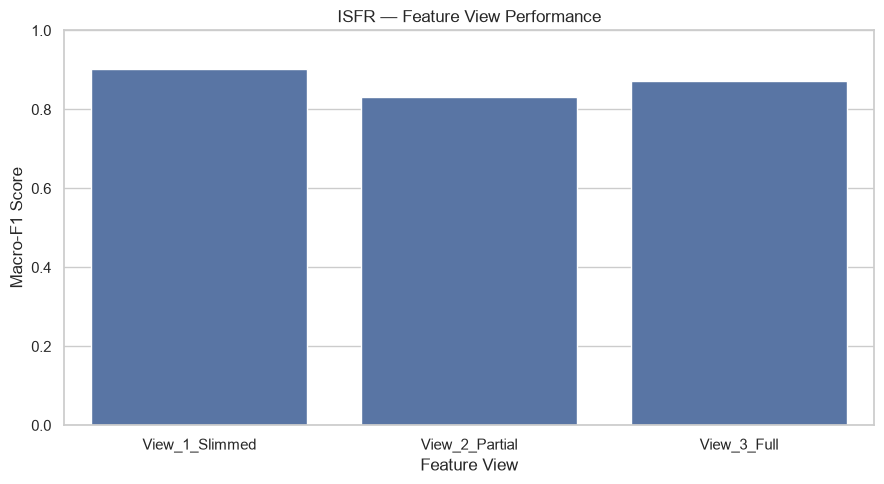

In [15]:
# Cell 12 — Compare Macro-F1 across views

plt.figure(figsize=(9, 5))

sns.barplot(
    data=isfr_results,
    x="View",
    y="Macro F1"
)

plt.ylim(0, 1)
plt.title("ISFR — Feature View Performance")
plt.ylabel("Macro-F1 Score")
plt.xlabel("Feature View")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "isfr_view_comparison.png",
    dpi=300
)

plt.show()

## ISFR Experimental Findings

Three successive feature views were evaluated using
the same Random Forest configuration.

View 1, containing 27 PCA components, achieved the
highest Macro-F1 score of 0.9013 and fraud recall
of 0.7215.

View 2, containing 72 features, achieved a Macro-F1
score of 0.8304.

View 3, containing 378 features, achieved a Macro-F1
score of 0.8721.

The results indicate that the interaction-expanded
representations did not improve classification
performance in this experiment.

The 27-component representation was selected as
the best-performing ISFR view based on validation
Macro-F1.

The results are specific to this implementation
and dataset. They do not establish the performance
of the exact published ISFR algorithm.